# Magnificent 7 — Stock Analysis, Portfolio Optimization & Risk Forecasting

**Assets:** AAPL, GOOG, META, AMZN, MSFT, NVDA, TSLA

## Project Overview

An end-to-end quantitative finance project combining **exploratory data analysis, risk-return analytics, benchmark evaluation, CAPM, Modern Portfolio Theory (MPT), constrained portfolio optimization, Monte Carlo simulation, Value at Risk (VaR), and portfolio backtesting**.

### Business / Investment Question

> How can historical market data be used to compare the Magnificent 7, construct a diversified portfolio with improved risk-adjusted performance, quantify downside risk, and evaluate portfolio-management strategies?

### Analytical Workflow

1. **Data Acquisition** — Five years of daily adjusted closing prices using `yfinance`
2. **EDA** — Price trends, normalized performance, moving averages
3. **Risk & Return** — Daily returns, annualized return/volatility, Beta, Sharpe Ratio, correlation
4. **Benchmarking** — Equal-weight Magnificent 7 vs S&P 500 and QQQ
5. **CAPM** — Systematic risk, expected return, and Jensen-style alpha
6. **Portfolio Optimization** — Efficient Frontier and maximum-Sharpe optimization with a 50% single-stock cap
7. **Risk Forecasting** — Individual-stock and correlated portfolio Monte Carlo simulations with VaR
8. **Strategy Backtest** — Monthly rebalancing vs Buy & Hold

> **Reproducibility:** Market data are fetched live from Yahoo Finance when the notebook is run, so results update with the latest available trading data.

## Importing Libraries


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from datetime import datetime
import warnings
import yfinance as yf

sns.set_style('whitegrid')
warnings.filterwarnings('ignore')
%matplotlib inline

## Data Acquisition

A fixed five-year window (2021–2025) daily **adjusted closing prices** is downloaded for the Magnificent 7.

The rolling window captures multiple market regimes, including the 2022 technology-sector correction and the strong AI-led rally that followed.

**Why adjusted prices?** Adjusted prices account for corporate actions such as stock splits and dividends, making them appropriate for return and portfolio analysis.

In [2]:
# -----------------------------------
# Data Acquisition
# -----------------------------------

tickers = ['AAPL', 'GOOG', 'META', 'AMZN', 'MSFT', 'NVDA', 'TSLA']

start_date = pd.Timestamp('2021-01-01')
end_date = pd.Timestamp('2025-12-31')

raw_data = yf.download(
    tickers,
    start=start_date,
    end=end_date + pd.Timedelta(days=1),
    auto_adjust=True,
    progress=False
)

if isinstance(raw_data.columns, pd.MultiIndex):
    data = raw_data['Close'].copy()
else:
    data = raw_data[['Close']].copy()
    data.columns = [tickers[0]]

data = data.reindex(columns=tickers).dropna(how='all').ffill().dropna()

if data.empty:
    raise ValueError(
        "No price data were downloaded. Check the internet connection or Yahoo Finance availability."
    )

print(f"Shape: {data.shape}")
print(f"Date range: {data.index[0].date()} to {data.index[-1].date()}")
print(f"Trading days: {len(data):,}")
data.tail()

Shape: (1255, 7)
Date range: 2021-01-04 to 2025-12-31
Trading days: 1,255


Ticker,AAPL,GOOG,META,AMZN,MSFT,NVDA,TSLA
Date,,,,,,,
2025-12-24,273.066711,315.053528,666.361328,232.380005,484.943420,188.380234,485.399994
2025-12-26,272.657806,314.344879,662.108948,232.520004,484.635406,190.297897,475.190002
2025-12-29,273.016876,313.776031,657.517151,232.070007,484.029236,187.990707,459.640015
2025-12-30,272.338684,313.935669,664.764221,232.529999,484.406860,187.311539,454.429993
2025-12-31,271.122009,313.187134,658.914612,230.820007,480.571167,186.272812,449.720001


In [3]:
# -----------------------------------
# Train/Test Split for Look-Ahead Bias Fix
# -----------------------------------
split_date = '2024-01-01'

data_estimation = data[data.index < split_date].copy()   # weights yahan se seekhega
data_evaluation = data[data.index >= split_date].copy()  # sab testing yahan hoga

print(f"Estimation window: {data_estimation.index[0].date()} to {data_estimation.index[-1].date()}")
print(f"Evaluation window: {data_evaluation.index[0].date()} to {data_evaluation.index[-1].date()}")

Estimation window: 2021-01-04 to 2023-12-29
Evaluation window: 2024-01-02 to 2025-12-31


##  Exploratory Data Analysis (EDA)

### Individual Closing Price Charts


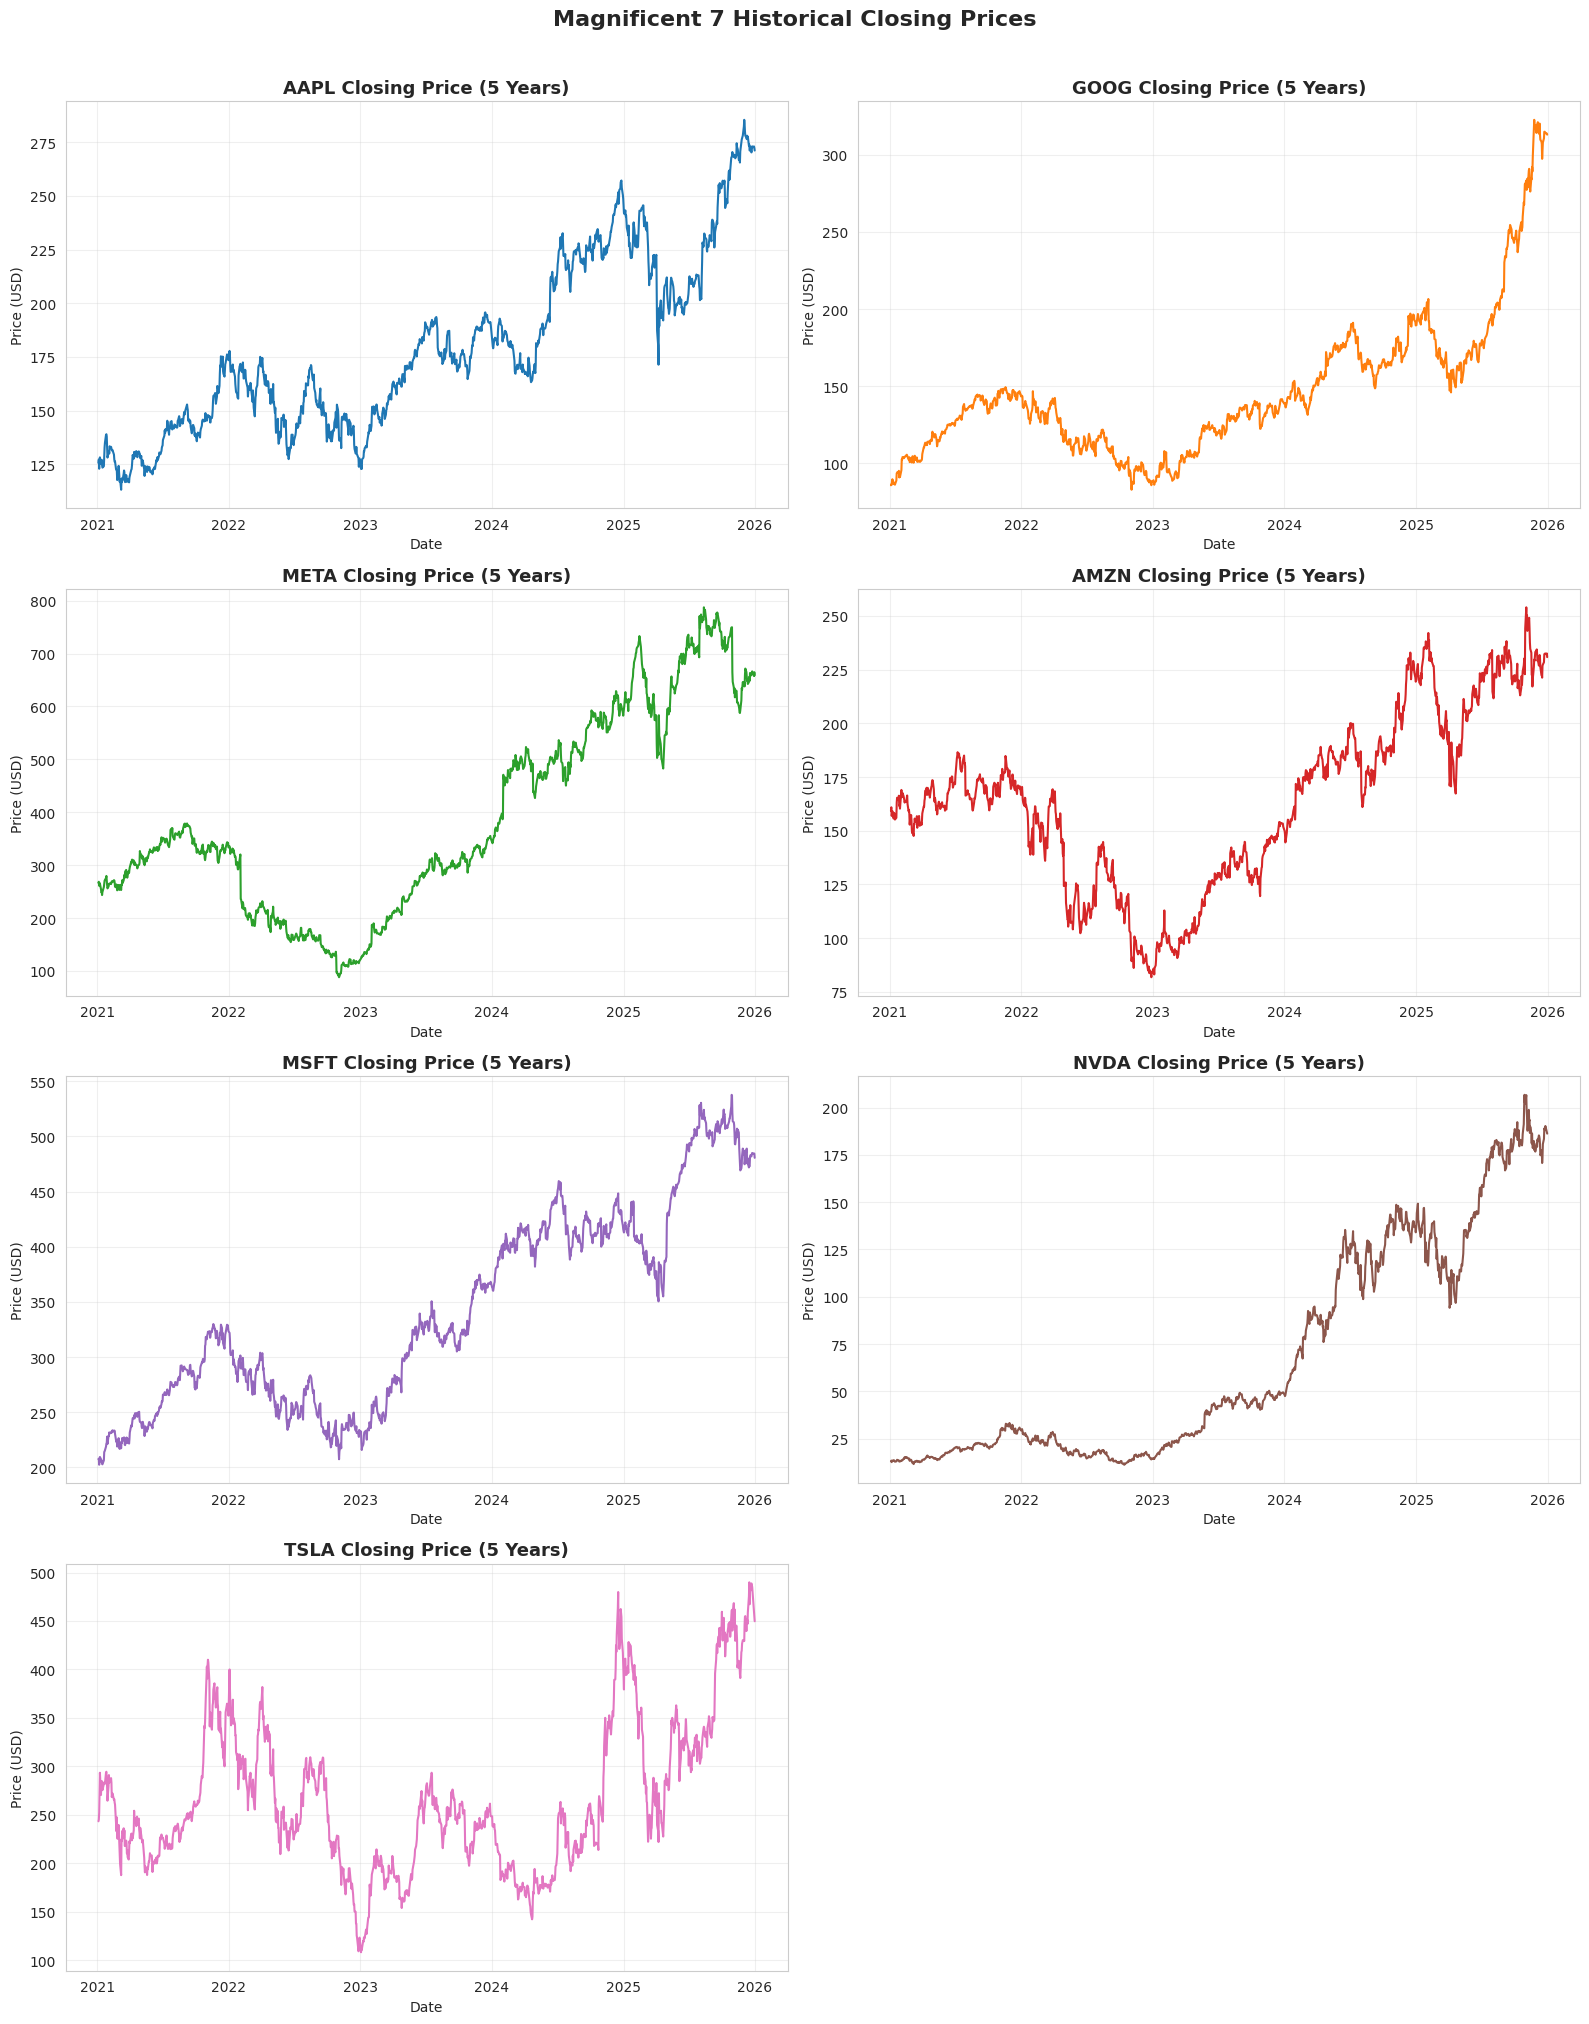

In [4]:
colors = sns.color_palette("tab10", len(tickers))

fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.flatten()

for i, ticker in enumerate(tickers):
    axes[i].plot(data.index, data[ticker], color=colors[i], linewidth=1.5)
    axes[i].set_title(f'{ticker} Closing Price (5 Years)', fontsize=13, fontweight='bold')
    axes[i].set_xlabel('Date')
    axes[i].set_ylabel('Price (USD)')
    axes[i].grid(True, alpha=0.3)

fig.delaxes(axes[7])
plt.suptitle('Magnificent 7 Historical Closing Prices', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### Insights

- The normalized and raw price charts reveal materially different growth paths across the Magnificent 7.
- NVIDIA shows the strongest long-run appreciation in the current sample, while Tesla exhibits much larger price fluctuations.
- Raw price levels are not directly comparable across stocks because each stock starts at a different price; normalized performance is therefore used for cross-stock comparison.

###  Normalized Price Comparison (Base = 100)

Normalizing to 100 at start lets us compare percentage growth fairly across all stocks.

Formula: Normalized = (Price / First Price) x 100


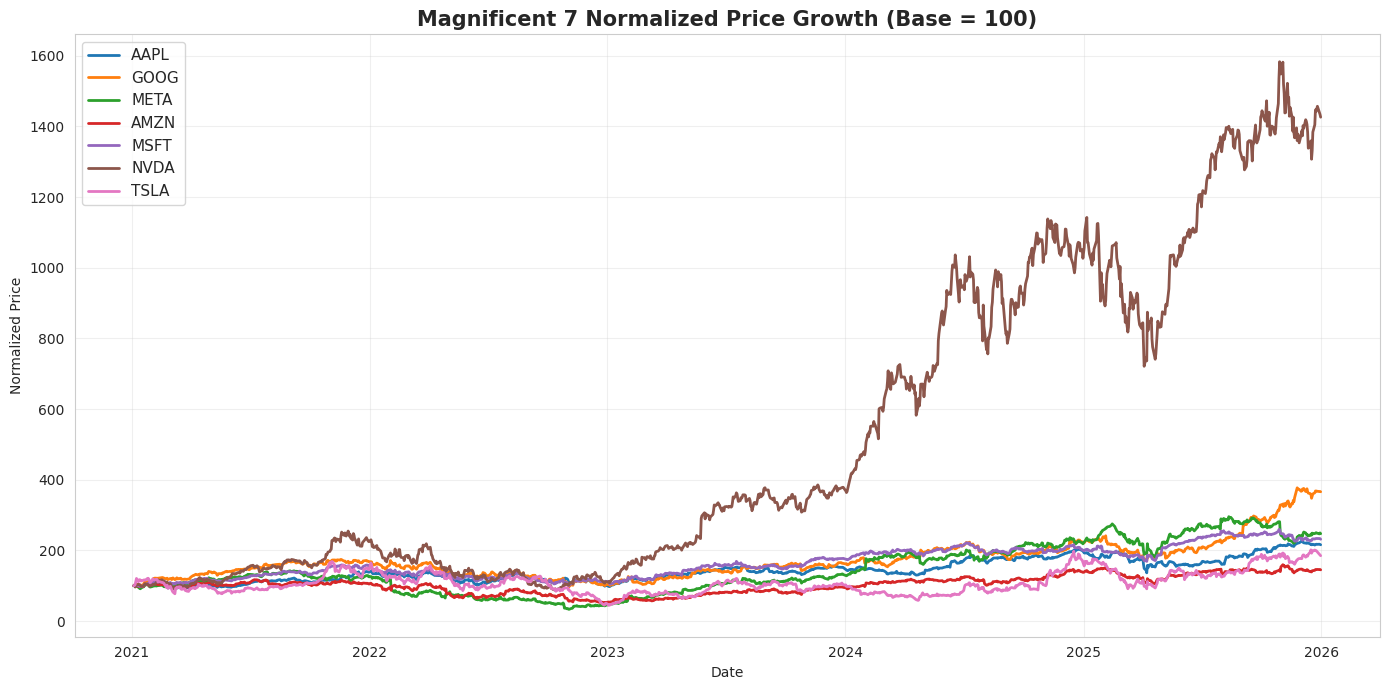

Cumulative Return Summary:
----------------------------------------
  AAPL : +115.8%
  GOOG : +265.9%
  META : +147.2%
  AMZN : +44.9%
  MSFT : +131.5%
  NVDA : +1326.2%
  TSLA : +84.9%


In [5]:
normalized = (data / data.iloc[0]) * 100

plt.figure(figsize=(14, 7))

for i, ticker in enumerate(tickers):
    plt.plot(
        normalized.index,
        normalized[ticker],
        label=ticker,
        color=colors[i],
        linewidth=2
    )

plt.title(
    'Magnificent 7 Normalized Price Growth (Base = 100)',
    fontsize=15,
    fontweight='bold'
)
plt.xlabel('Date')
plt.ylabel('Normalized Price')
plt.legend(loc='upper left', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('Cumulative Return Summary:')
print('-' * 40)

for ticker in tickers:
    r = (data[ticker].iloc[-1] / data[ticker].iloc[0] - 1) * 100
    print(f'  {ticker:5s}: {r:+.1f}%')

### Key Insights

- Normalization to a common base of 100 makes cumulative performance directly comparable across stocks.
- The relative gap between stocks highlights substantial dispersion in historical performance within the Magnificent 7.
- Strong cumulative performance should always be evaluated alongside volatility, drawdown, and correlation rather than in isolation.

###  Moving Averages (Google deep dive)

Moving averages smooth short-term noise to reveal longer-term trends.

- 10-day MA: Short-term trend
- 25-day MA: Medium-term trend
- 50-day MA: Long-term sentiment indicator

- Golden Cross: MA_10 crosses ABOVE MA_50 = Bullish signal
- Death Cross: MA_10 crosses BELOW MA_50 = Bearish signal


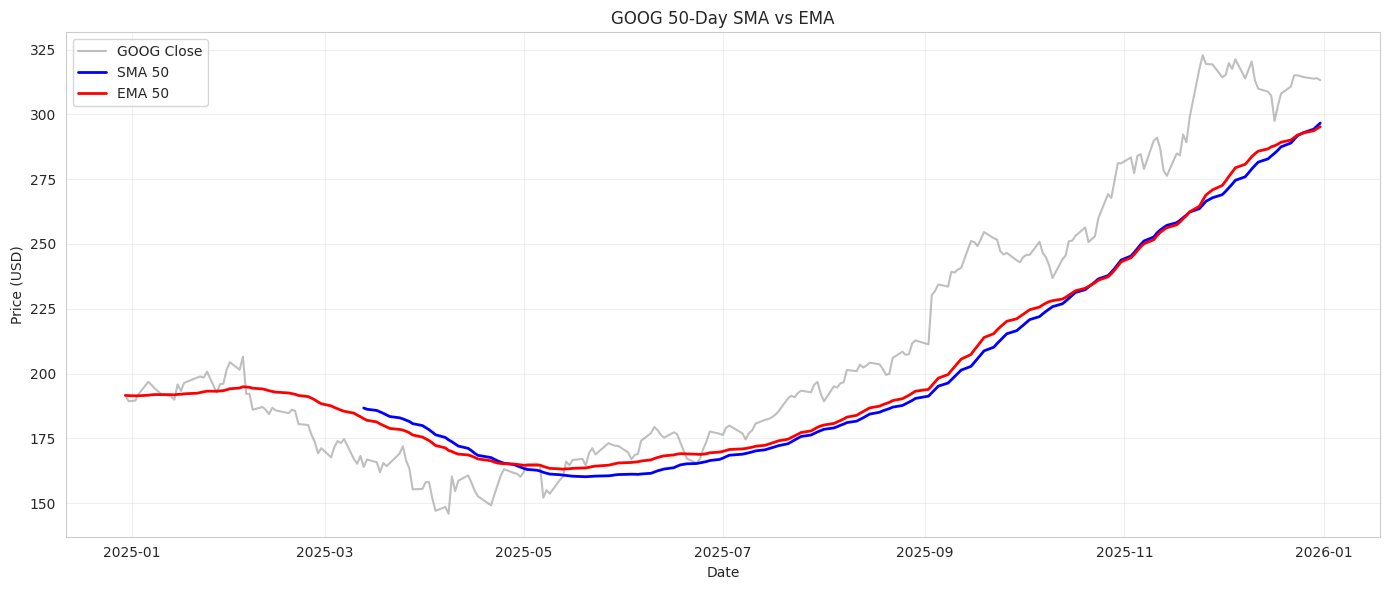

In [6]:
goog_1yr = data[['GOOG']].tail(252).copy()

goog_1yr['SMA_10'] = goog_1yr['GOOG'].rolling(window=10).mean()
goog_1yr['SMA_25'] = goog_1yr['GOOG'].rolling(window=25).mean()
goog_1yr['SMA_50'] = goog_1yr['GOOG'].rolling(window=50).mean()

goog_1yr['EMA_10'] = goog_1yr['GOOG'].ewm(span=10, adjust=False).mean()
goog_1yr['EMA_25'] = goog_1yr['GOOG'].ewm(span=25, adjust=False).mean()
goog_1yr['EMA_50'] = goog_1yr['GOOG'].ewm(span=50, adjust=False).mean()

plt.figure(figsize=(14, 6))

plt.plot(
    goog_1yr['GOOG'],
    label='GOOG Close',
    color='gray',
    alpha=0.5
)

plt.plot(
    goog_1yr['SMA_50'],
    label='SMA 50',
    color='blue',
    linewidth=2
)

plt.plot(
    goog_1yr['EMA_50'],
    label='EMA 50',
    color='red',
    linewidth=2
)

plt.title('GOOG 50-Day SMA vs EMA')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Insights

- The EMA responds more quickly to recent price movements than the SMA because it assigns greater weight to recent observations.
- The SMA provides a smoother view of the underlying trend and is less sensitive to short-term noise.
- Crossovers and divergence between the moving averages can be used as descriptive trend indicators, but they are not standalone trading signals.

## Risk & Return Analysis

### Daily Returns Distribution

Daily Return = (Today - Yesterday) / Yesterday

Wider distribution = more volatile = higher risk.


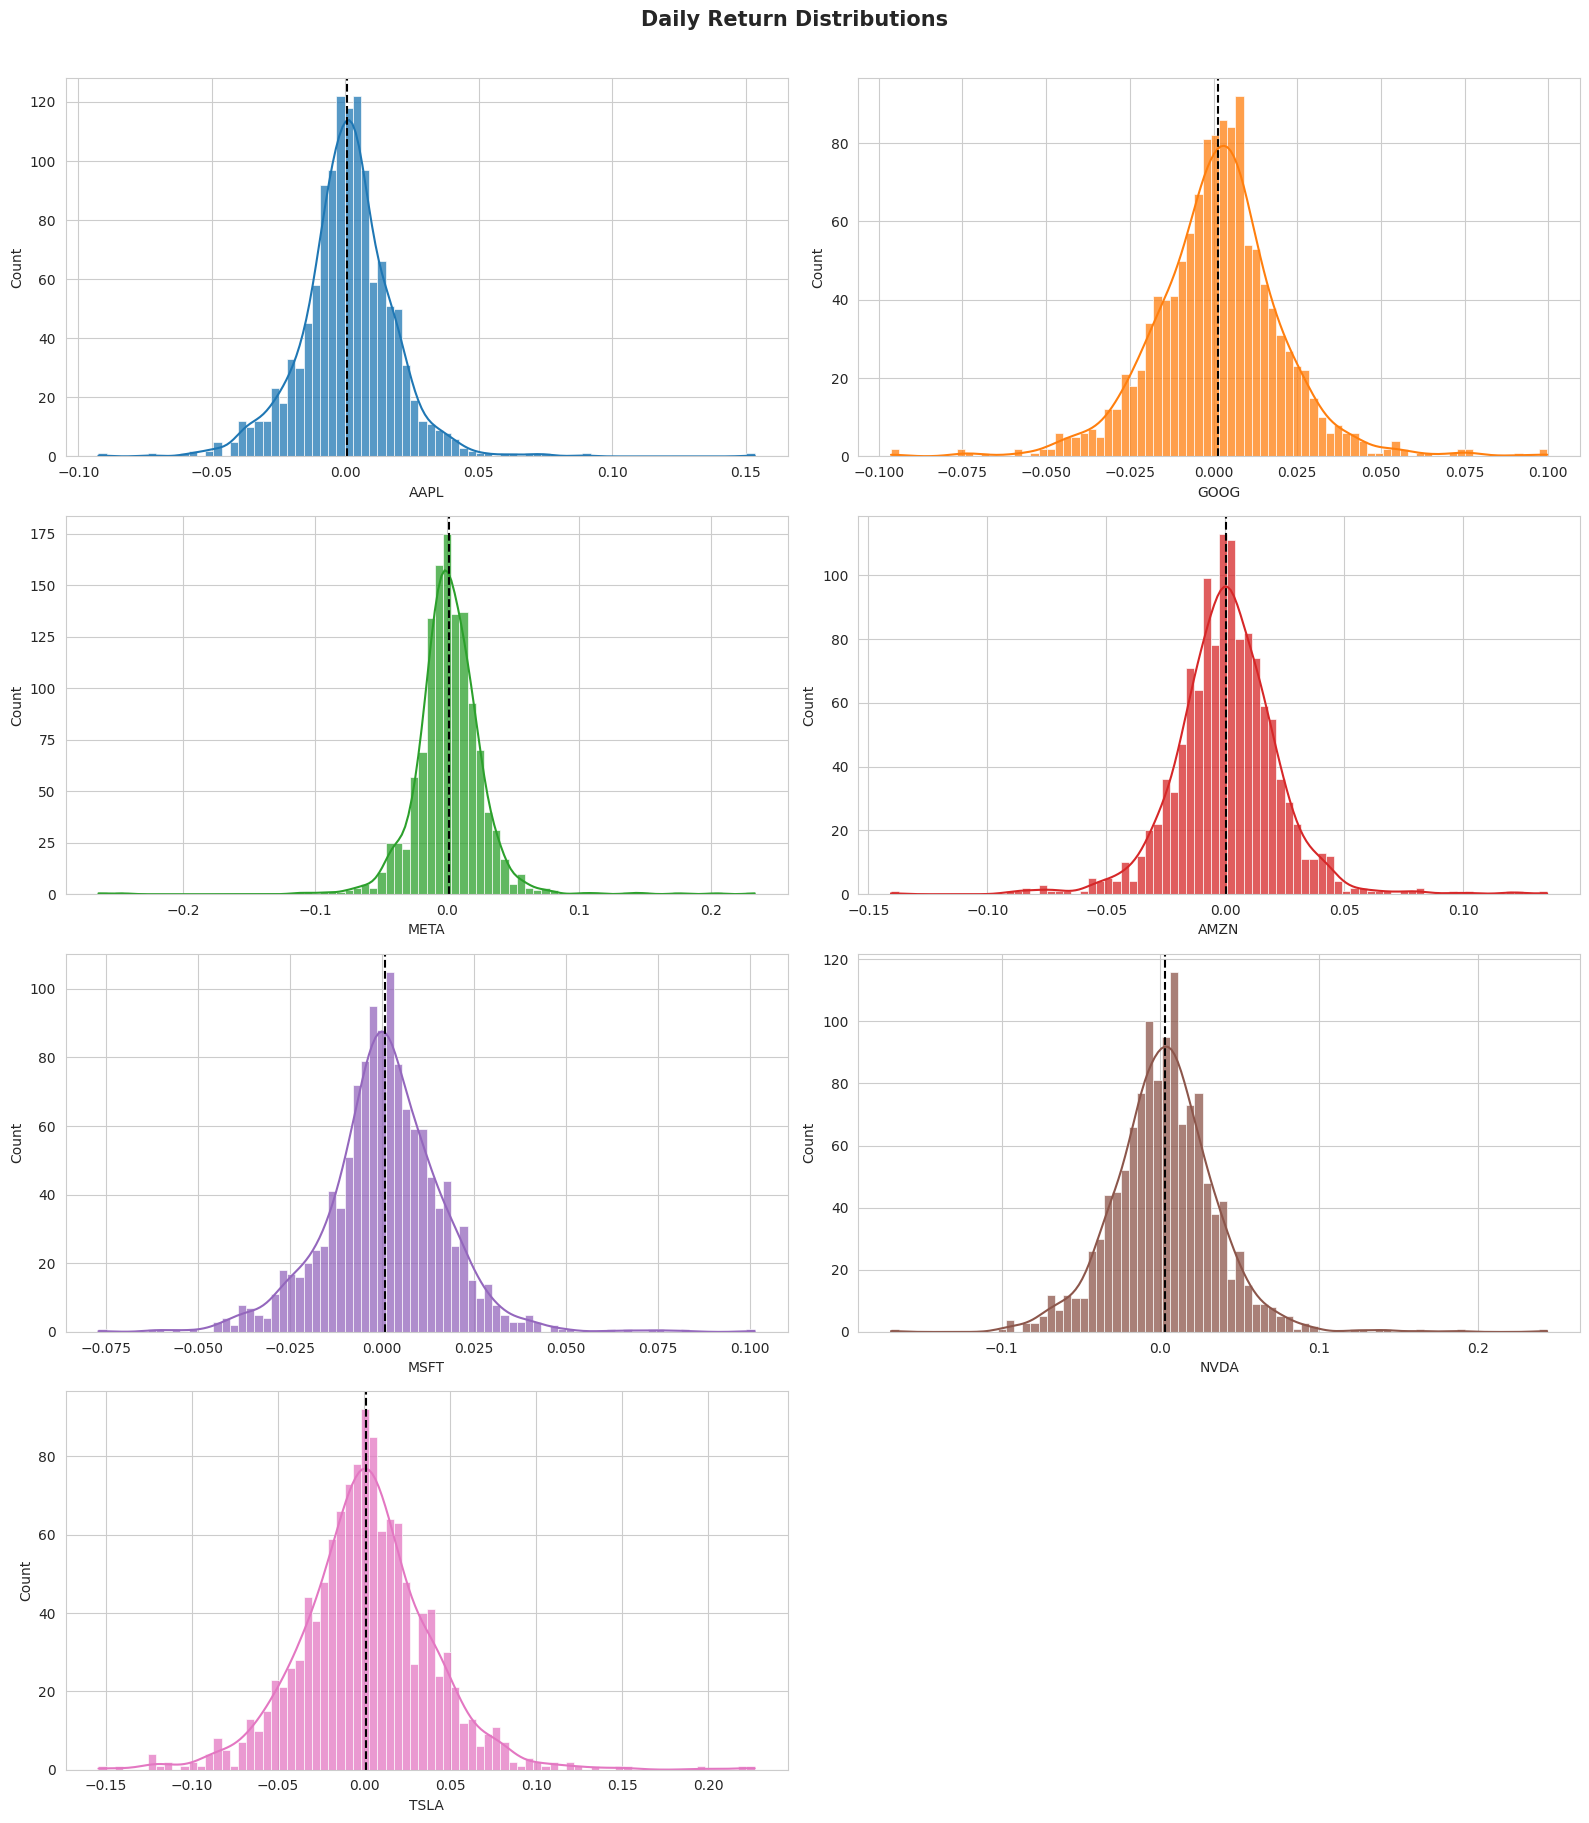

In [7]:
daily_returns = data.pct_change().dropna()

fig, axes = plt.subplots(4, 2, figsize=(16, 18))
axes = axes.flatten()

for i, ticker in enumerate(tickers):

    sns.histplot(
        daily_returns[ticker],
        bins=80,
        kde=True,
        color=colors[i],
        alpha=0.75,
        edgecolor='white',
        ax=axes[i]
    )

    axes[i].axvline(
        daily_returns[ticker].mean(),
        color='black',
        linestyle='--',
        linewidth=1.5,
        label='Mean'
    )

fig.delaxes(axes[7])
plt.suptitle('Daily Return Distributions', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### Insights

- Most daily returns cluster around zero, while high-volatility stocks show wider distributions and more extreme observations.
- The presence of extreme observations motivates explicit risk analysis rather than relying only on average returns.
- Return distributions provide the foundation for the volatility, correlation, Sharpe, CAPM, and Monte Carlo analyses that follow.

## Normality Testing of Daily Returns

Financial models often assume stock returns follow a normal distribution.  
This section tests whether the daily returns of the Magnificent 7 stocks are statistically normally distributed using the D’Agostino-Pearson normality test.

A p-value below 0.05 indicates rejection of the normality assumption.

Normality Test (D'Agostino-Pearson K² Test)
---------------------------------------------
  AAPL : p=0.0000  →  Normal ✗
  GOOG : p=0.0000  →  Normal ✗
  META : p=0.0000  →  Normal ✗
  AMZN : p=0.0000  →  Normal ✗
  MSFT : p=0.0000  →  Normal ✗
  NVDA : p=0.0000  →  Normal ✗
  TSLA : p=0.0000  →  Normal ✗


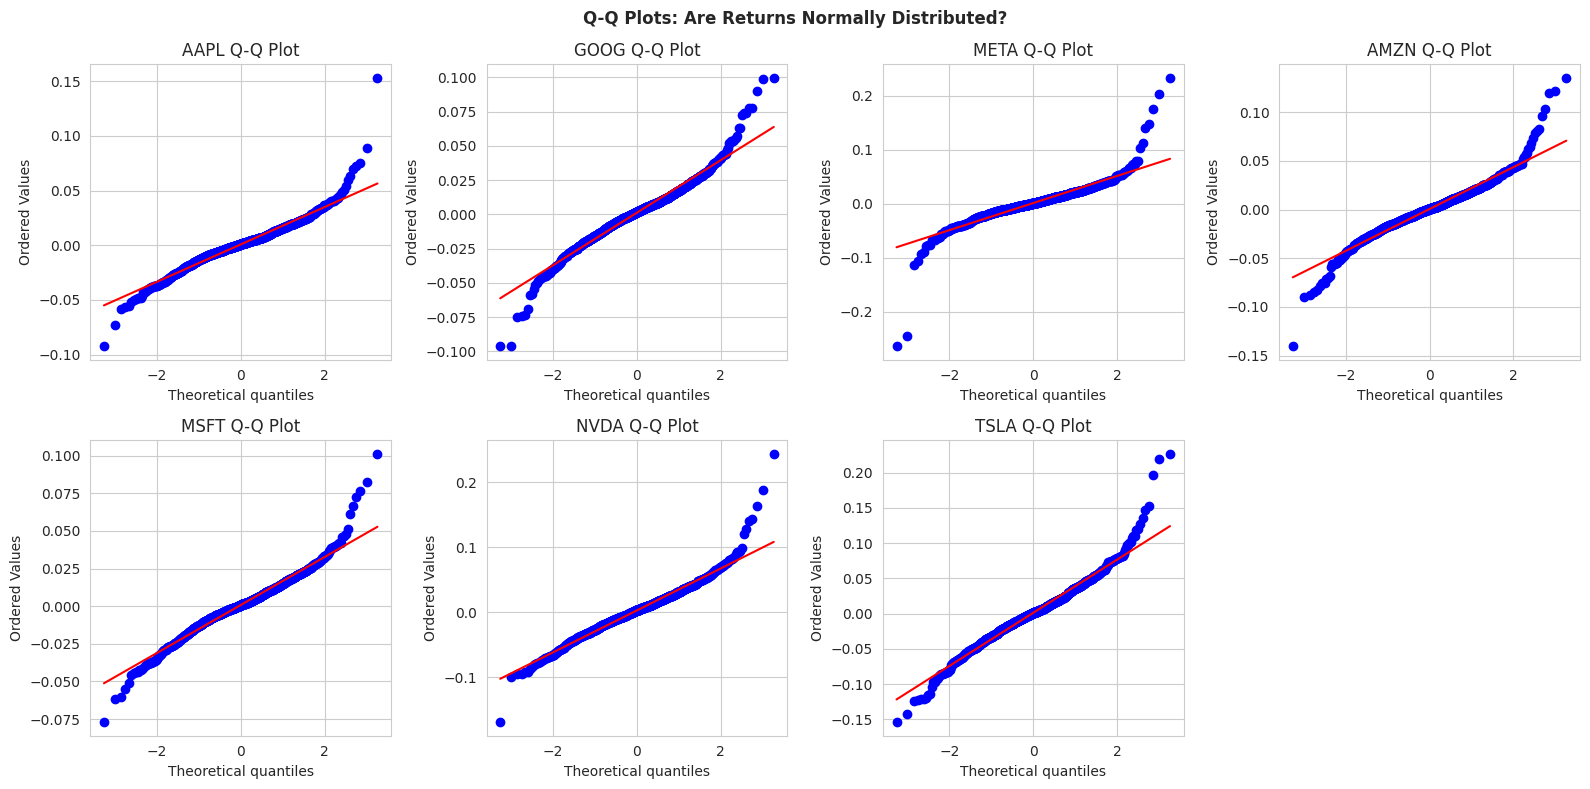

In [8]:
from scipy import stats

print("Normality Test (D'Agostino-Pearson K² Test)")
print("-" * 45)
for ticker in tickers:
    stat, p = stats.normaltest(daily_returns[ticker].dropna())
    result = "Normal ✗" if p < 0.05 else "Normal ✓"
    print(f"  {ticker:5s}: p={p:.4f}  →  {result}")

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
for i, ticker in enumerate(tickers):
    stats.probplot(daily_returns[ticker].dropna(), plot=axes[i])
    axes[i].set_title(f'{ticker} Q-Q Plot')
fig.delaxes(axes[7])
plt.suptitle('Q-Q Plots: Are Returns Normally Distributed?', fontweight='bold')
plt.tight_layout()
plt.show()

## Key Findings — Distribution & Normality

- The normality tests reject the normal-return assumption for the Magnificent 7 at the 5% significance level.
- Q-Q plots reveal heavier tails and departures from normality, especially for the more volatile stocks.
- This matters for risk management because extreme observations can occur more often than a simple normal model suggests.
- **Modeling implication:** GBM Monte Carlo is used as a transparent baseline scenario model, not as a claim that real-world returns are perfectly log-normal. The simulation results should therefore be interpreted as probabilistic estimates rather than precise forecasts.

### Risk–Return Profile

The analysis compares stocks using:

- **Annualized Return** = mean daily return × 252
- **Annualized Volatility** = daily standard deviation × √252
- **Beta** = sensitivity of stock returns to S&P 500 returns
- **Sharpe Ratio** = (annualized return − risk-free rate) / annualized volatility

A desirable risk-return profile combines higher expected return with lower volatility.

Risk-free rate: 4.16% (10-Year US Treasury yield, as of 2025-12-31)
Risk-Return Summary:
      Annual Return (%)  Annual Volatility (%)   Beta  Sharpe Ratio
AAPL              19.32                  27.86  1.245         0.544
GOOG              30.87                  30.97  1.264         0.862
META              27.72                  43.41  1.601         0.543
AMZN              13.60                  35.11  1.484         0.269
MSFT              20.17                  25.71  1.154         0.623
NVDA              66.95                  52.22  2.166         1.202
TSLA              30.66                  60.74  2.053         0.436


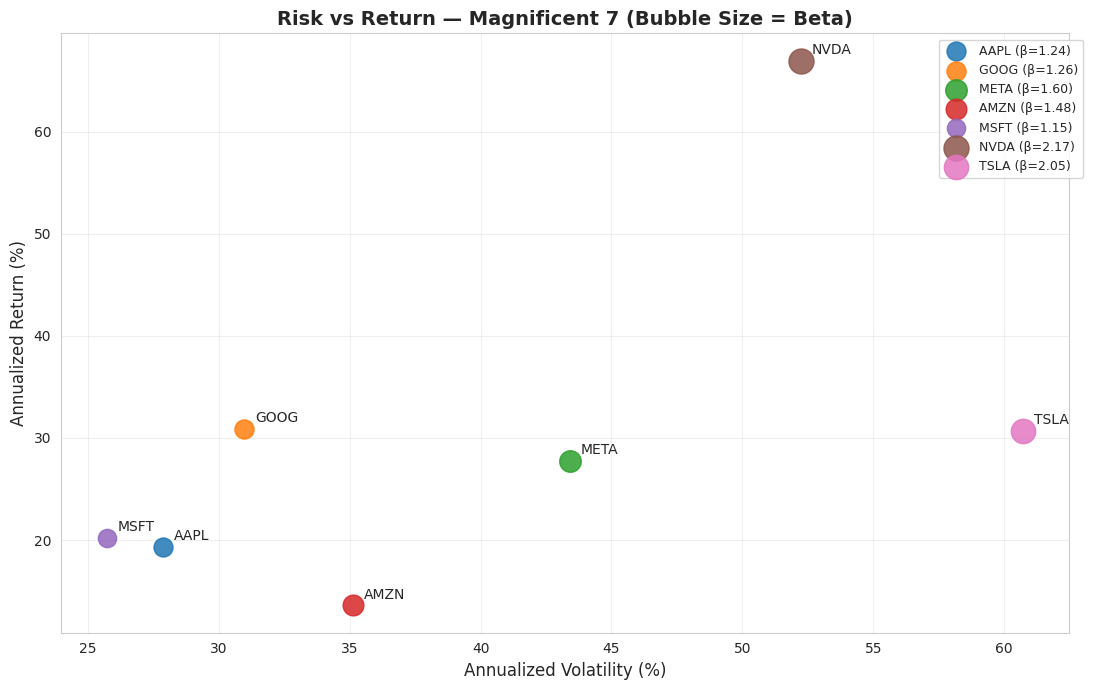

In [9]:
# -----------------------------------
# Risk-Return, Beta & Sharpe Analysis
# -----------------------------------

sp500_raw = yf.download(
    '^GSPC',
    start=start_date,
    end=end_date + pd.Timedelta(days=1),
    auto_adjust=True,
    progress=False
)

if isinstance(sp500_raw.columns, pd.MultiIndex):
    sp500 = sp500_raw['Close'].squeeze()
else:
    sp500 = sp500_raw['Close'].squeeze()

sp500 = pd.Series(sp500).dropna()
market_returns = sp500.pct_change().dropna()

annual_returns = daily_returns.mean() * 252
annual_vol = daily_returns.std() * np.sqrt(252)

# -----------------------------------
# Risk-free rate — sourced dynamically (10-Year US Treasury yield)
# -----------------------------------
rf_data = yf.download(
    '^TNX',
    start=start_date,
    end=end_date + pd.Timedelta(days=1),
    progress=False
)

if isinstance(rf_data.columns, pd.MultiIndex):
    rf_close = rf_data['Close'].squeeze()
else:
    rf_close = rf_data['Close'].squeeze()

rf_close = pd.Series(rf_close).dropna()
risk_free_rate = rf_close.iloc[-1] / 100   # ^TNX is quoted in %, so divide by 100
rf_date = rf_close.index[-1].strftime('%Y-%m-%d')

print(f"Risk-free rate: {risk_free_rate*100:.2f}% (10-Year US Treasury yield, as of {rf_date})")

def calculate_beta(stock_ret, mkt_ret):
    aligned = pd.concat([stock_ret, mkt_ret], axis=1).dropna()
    return np.cov(
        aligned.iloc[:, 0],
        aligned.iloc[:, 1],
        ddof=1
    )[0, 1] / np.var(aligned.iloc[:, 1], ddof=1)

betas = {
    ticker: calculate_beta(daily_returns[ticker], market_returns)
    for ticker in tickers
}

sharpe_ratios = (annual_returns - risk_free_rate) / annual_vol

summary_df = pd.DataFrame({
    'Annual Return (%)': (annual_returns * 100).round(2),
    'Annual Volatility (%)': (annual_vol * 100).round(2),
    'Beta': pd.Series(betas).round(3),
    'Sharpe Ratio': sharpe_ratios.round(3)
})

print('Risk-Return Summary:')
print(summary_df.to_string())

plt.figure(figsize=(11, 7))

for i, ticker in enumerate(tickers):
    plt.scatter(
        annual_vol[ticker] * 100,
        annual_returns[ticker] * 100,
        s=max(betas[ticker], 0.1) * 150,
        color=colors[i],
        alpha=0.85,
        label=f'{ticker} (β={betas[ticker]:.2f})'
    )

    plt.annotate(
        ticker,
        (annual_vol[ticker] * 100, annual_returns[ticker] * 100),
        textcoords='offset points',
        xytext=(8, 5),
        fontsize=10
    )

plt.xlabel('Annualized Volatility (%)', fontsize=12)
plt.ylabel('Annualized Return (%)', fontsize=12)
plt.title(
    'Risk vs Return — Magnificent 7 (Bubble Size = Beta)',
    fontsize=14,
    fontweight='bold'
)
plt.legend(bbox_to_anchor=(1.02, 1), fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Insights

- NVIDIA achieved the strongest overall performance, delivering the highest annualized return (67%) and the best Sharpe Ratio (1.20), indicating superior risk-adjusted returns despite its high volatility.

- Tesla exhibited the highest volatility and one of the largest beta values, confirming that it is the most aggressive and market-sensitive stock among the Magnificent 7.

- Amazon & Google provided the most balanced risk-return profiles, combining comparatively lower volatility with stable long-term returns.

- Microsoft and Apple exhibited strong risk-adjusted performance, combining relatively stable returns with lower volatility than many growth-oriented stocks.

- Stocks with beta values significantly greater than 1, such as NVIDIA and Tesla, showed stronger sensitivity to overall market movements and larger price fluctuations.

### Correlation Heatmap

Correlation measures how similarly two stocks move together.

+1.0 = Move perfectly together
0.0 = No relationship
-1.0 = Move in opposite directions

High correlation among all 7 = limited diversification within this group alone.


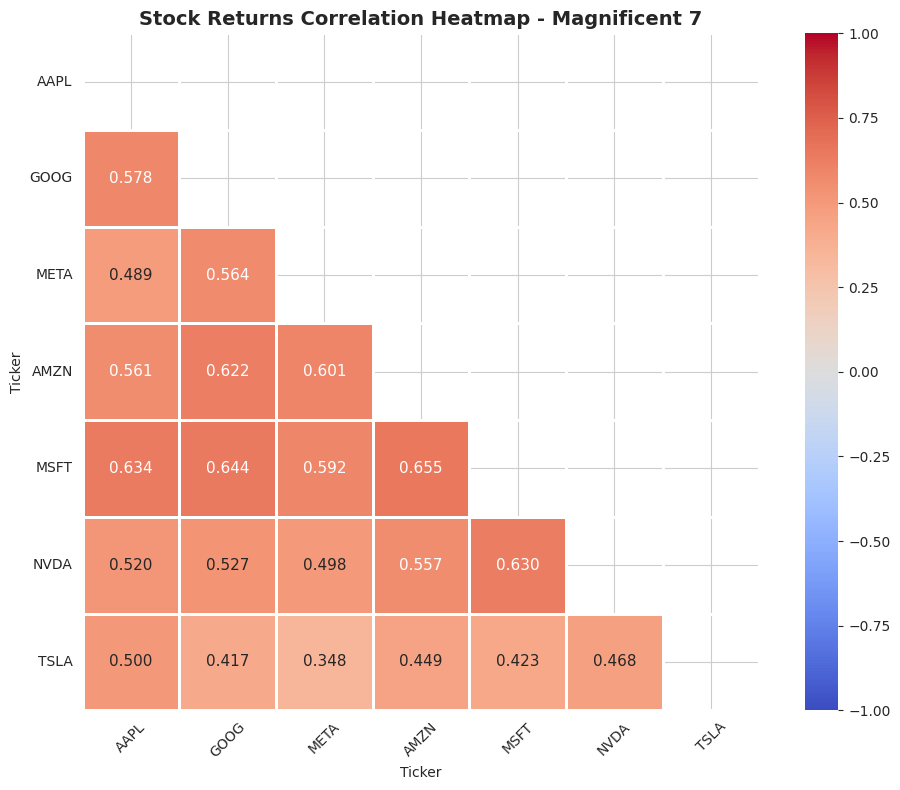

Highest correlated pair: MSFT & AMZN (0.655)
These two stocks tend to move most similarly.


In [10]:
corr_matrix = daily_returns.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.8,
    linecolor='white',
    annot_kws={'size': 11}
)
plt.title('Stock Returns Correlation Heatmap - Magnificent 7', fontsize=14, fontweight='bold')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

corr_vals = corr_matrix.unstack()
corr_vals = corr_vals[corr_vals < 1.0].sort_values(ascending=False)
top_pair = corr_vals.index[0]
print(f'Highest correlated pair: {top_pair[0]} & {top_pair[1]} ({corr_vals.iloc[0]:.3f})')
print('These two stocks tend to move most similarly.')

### Key Insights

- Positive correlations across the Magnificent 7 indicate that diversification within this group is helpful but incomplete.
- Lower-correlation pairs can provide greater diversification benefits than highly correlated pairs.
- Because the assets are exposed to common technology, growth, and macroeconomic drivers, the group remains vulnerable to broad sector-level drawdowns.

## Benchmark Comparison

The equal-weight Magnificent 7 portfolio is compared with the **S&P 500** and **QQQ** using a common base of 100.

This section evaluates whether a simple diversified allocation to the Magnificent 7 historically outperformed broad-market and technology-heavy benchmarks.

> The benchmark differences reported below are **cumulative excess returns**, not CAPM/Jensen alpha. Formal alpha is evaluated separately in the CAPM section.

In [11]:
# -----------------------------------
# Benchmark Comparison Preparation
# -----------------------------------

equal_weights = np.repeat(1 / len(tickers), len(tickers))

m7_daily_ret = daily_returns.dot(equal_weights)
m7_c = (1 + m7_daily_ret).cumprod() * 100

def download_close(symbol):
    raw = yf.download(
        symbol,
        start=start_date,
        end=end_date + pd.Timedelta(days=1),
        auto_adjust=True,
        progress=False
    )

    if isinstance(raw.columns, pd.MultiIndex):
        close = raw['Close'].squeeze()
    else:
        close = raw['Close'].squeeze()

    return pd.Series(close).dropna()

sp500 = download_close('^GSPC')
sp500_aligned = sp500.reindex(data.index).ffill()
sp500_daily = sp500_aligned.pct_change().dropna()
sp5_c = (1 + sp500_daily).cumprod() * 100

qqq = download_close('QQQ')
qqq_aligned = qqq.reindex(data.index).ffill()
qqq_daily = qqq_aligned.pct_change().dropna()
qqq_c = (1 + qqq_daily).cumprod() * 100

benchmark_df = pd.concat(
    [
        m7_c.rename('M7'),
        sp5_c.rename('S&P 500'),
        qqq_c.rename('QQQ')
    ],
    axis=1
).dropna()

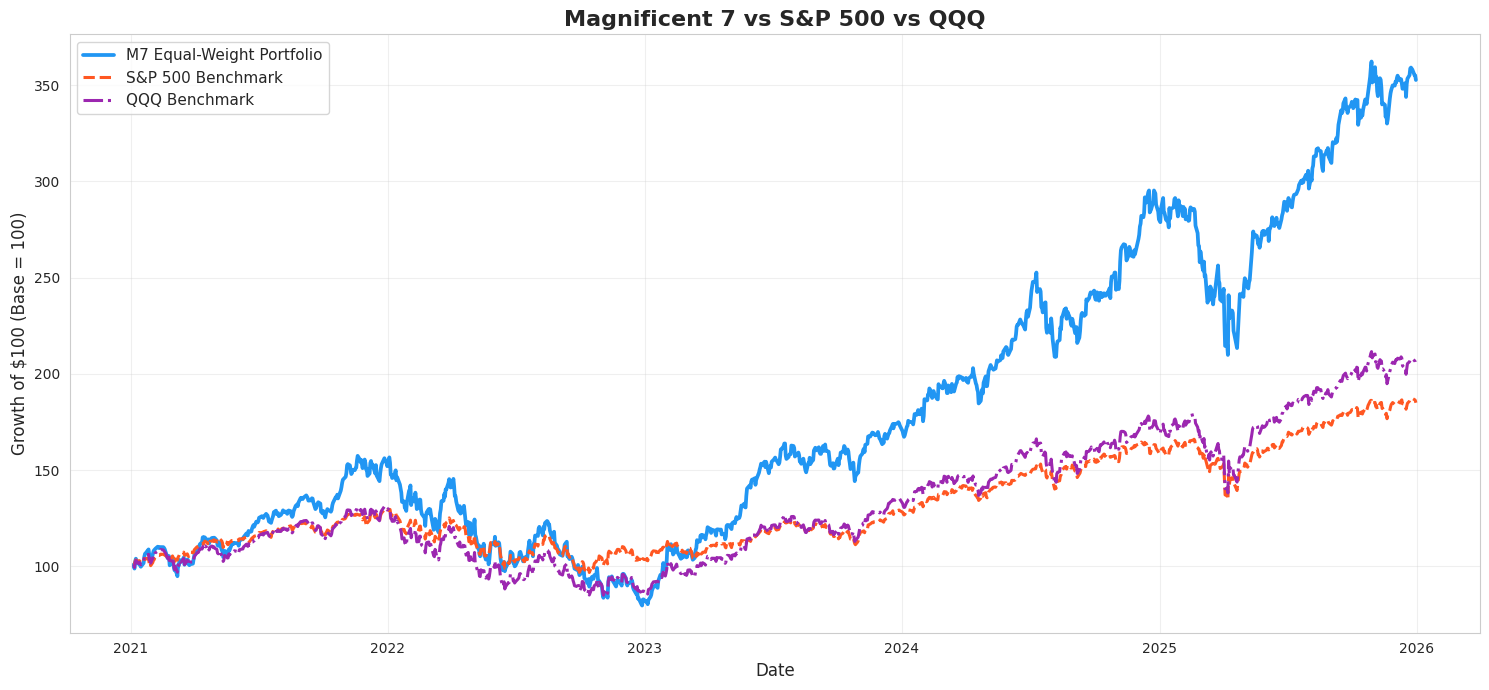


Cumulative Returns
----------------------------------------
M7 Portfolio : +252.6%
S&P 500      : +85.0%
QQQ          : +104.7%

Cumulative Excess Return vs Benchmarks
----------------------------------------
vs S&P 500 : +167.6%
vs QQQ     : +148.0%


In [12]:
plt.figure(figsize=(15, 7))

sns.lineplot(
    x=benchmark_df.index,
    y=benchmark_df['M7'],
    label='M7 Equal-Weight Portfolio',
    linewidth=2.7,
    color='#2196F3'
)

sns.lineplot(
    x=benchmark_df.index,
    y=benchmark_df['S&P 500'],
    label='S&P 500 Benchmark',
    linewidth=2.2,
    linestyle='--',
    color='#FF5722'
)

sns.lineplot(
    x=benchmark_df.index,
    y=benchmark_df['QQQ'],
    label='QQQ Benchmark',
    linewidth=2.2,
    linestyle='-.',
    color='#9C27B0'
)

plt.title(
    'Magnificent 7 vs S&P 500 vs QQQ',
    fontsize=16,
    fontweight='bold'
)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Growth of $100 (Base = 100)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

m7_return = benchmark_df['M7'].iloc[-1] - 100
sp500_ret = benchmark_df['S&P 500'].iloc[-1] - 100
qqq_ret = benchmark_df['QQQ'].iloc[-1] - 100

print('\nCumulative Returns')
print('-' * 40)
print(f'M7 Portfolio : {m7_return:+.1f}%')
print(f'S&P 500      : {sp500_ret:+.1f}%')
print(f'QQQ          : {qqq_ret:+.1f}%')

print('\nCumulative Excess Return vs Benchmarks')
print('-' * 40)
print(f'vs S&P 500 : {m7_return - sp500_ret:+.1f}%')
print(f'vs QQQ     : {m7_return - qqq_ret:+.1f}%')

### Key Insights

- The benchmark comparison shows whether a simple equal-weight Magnificent 7 portfolio historically added value relative to broad-market and technology-sector benchmarks.
- Strong outperformance, if observed, should be interpreted alongside the portfolio's higher concentration and drawdown risk.
- Comparing against QQQ is particularly useful because QQQ already has substantial exposure to large technology companies.
- Benchmark-relative performance is descriptive of the selected historical window and should not be interpreted as a forecast of future returns.

## Maximum Drawdown Analysis

Maximum Drawdown measures the largest percentage decline from a portfolio’s previous peak value. It helps evaluate downside risk and the severity of historical portfolio crashes.

In [13]:
# Function to calculate max drawdown
def max_drawdown(series):

    rolling_max = series.cummax()

    drawdown = (series - rolling_max) / rolling_max

    return drawdown.min() * 100


# Calculate drawdowns
m7_drawdown  = max_drawdown(m7_c)
sp500_drawdown = max_drawdown(sp5_c)
qqq_drawdown = max_drawdown(qqq_c)

print('Maximum Drawdown Analysis')
print('-' * 40)

print(f'M7 Portfolio : {m7_drawdown:.2f}%')
print(f'S&P 500       : {sp500_drawdown:.2f}%')
print(f'QQQ ETF       : {qqq_drawdown:.2f}%')

Maximum Drawdown Analysis
----------------------------------------
M7 Portfolio : -49.39%
S&P 500       : -25.43%
QQQ ETF       : -35.12%


### Key Insights

- Maximum drawdown highlights the severity of historical peak-to-trough losses that are not captured by volatility alone.
- The Magnificent 7 portfolio can deliver strong long-run growth while still experiencing substantial interim drawdowns.
- The result reinforces the central portfolio-management tradeoff: **higher return potential can come with higher downside risk and concentration exposure**.

## CAPM Analysis

The Capital Asset Pricing Model (CAPM) estimates a stock's expected return from its systematic market risk.

**CAPM Expected Return = Risk-Free Rate + Beta × (Market Return − Risk-Free Rate)**

A Jensen-style alpha is then calculated as:

**Alpha = Actual Annualized Return − CAPM Expected Return**

- Positive alpha → historical return exceeded the CAPM-implied return
- Negative alpha → historical return was below the CAPM-implied return

**Risk-free rate: sourced dynamically from the 10-Year US Treasury yield (^TNX), used consistently in the Sharpe and CAPM calculations.

CAPM Analysis Results:
        Beta  CAPM Expected Return (%)  Actual Return (%)  Alpha (%)
Stock                                                               
AAPL   1.245                     16.16              19.32       3.17
GOOG   1.264                     16.34              30.87      14.52
META   1.601                     19.59              27.72       8.13
AMZN   1.484                     18.46              13.60      -4.86
MSFT   1.154                     15.29              20.17       4.89
NVDA   2.166                     25.03              66.95      41.92
TSLA   2.053                     23.94              30.66       6.72


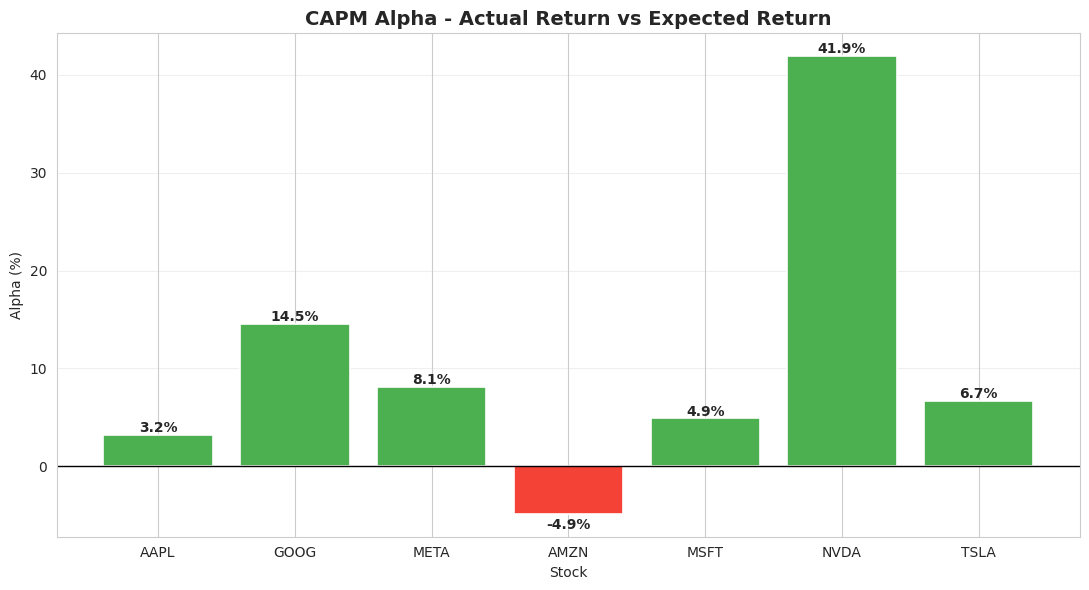

In [14]:
market_annual_return = market_returns.squeeze().mean() * 252

capm_results = []
for ticker in tickers:
    beta    = betas[ticker]
    exp_ret = risk_free_rate + beta * (market_annual_return - risk_free_rate)
    act_ret = annual_returns[ticker]
    alpha   = act_ret - exp_ret
    capm_results.append({
        'Stock': ticker,
        'Beta': round(beta, 3),
        'CAPM Expected Return (%)': round(exp_ret * 100, 2),
        'Actual Return (%)': round(act_ret * 100, 2),
        'Alpha (%)': round(alpha * 100, 2)
    })

capm_df = pd.DataFrame(capm_results).set_index('Stock')
print('CAPM Analysis Results:')
print(capm_df.to_string())

fig, ax = plt.subplots(figsize=(11, 6))
bar_colors = ['#4CAF50' if x > 0 else '#F44336' for x in capm_df['Alpha (%)']]
bars = ax.bar(capm_df.index, capm_df['Alpha (%)'], color=bar_colors, edgecolor='white', linewidth=1.2)
ax.axhline(y=0, color='black', linewidth=1)
ax.set_title('CAPM Alpha - Actual Return vs Expected Return', fontsize=14, fontweight='bold')
ax.set_ylabel('Alpha (%)')
ax.set_xlabel('Stock')
for bar, val in zip(bars, capm_df['Alpha (%)']):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + (0.3 if val >= 0 else -1.5),
            f'{val:.1f}%', ha='center', fontsize=10, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

### Key Insights

- CAPM separates **absolute performance** from performance attributable to systematic market exposure.
- A positive alpha indicates that the stock's historical return exceeded its CAPM-implied return over this sample.
- NVIDIA's high beta and strong historical return make it an important case study in the tradeoff between exceptional performance and elevated systematic risk.
- CAPM is a simplified single-factor model; the calculated alpha is sample-period dependent and should not be treated as a guaranteed future excess return.

## Portfolio Optimization using Modern Portfolio Theory (MPT)

Modern Portfolio Theory (MPT) evaluates portfolios using the tradeoff between **expected return and volatility**.

### Optimization design

- 20,000 feasible random portfolios are generated under the same **50% maximum allocation per stock** constraint.
- The **Sharpe Ratio** is used as the optimization objective.
- A constrained SLSQP optimizer searches for the exact maximum-Sharpe allocation.
- A **50% single-stock cap** controls concentration risk after comparing the unconstrained solution with the constrained solution.

The project reports both:
1. **Unconstrained maximum-Sharpe portfolio** — diagnostic benchmark
2. **50%-capped maximum-Sharpe portfolio** — final diversified portfolio

This makes the allocation decision transparent rather than hiding the concentration problem of an unconstrained optimizer.

To avoid look-ahead bias, weights are fit on an estimation window (2021–2023) and all downstream evaluation — Monte Carlo simulation, VaR, and the rebalancing backtest — is performed on a held-out evaluation window (2024–2025) that the optimizer never sees.

Portfolio Optimization Results

Unconstrained Maximum-Sharpe Portfolio:
   Annualized Return    : 58.47%
   Annualized Volatility: 53.00%
   Sharpe Ratio         : 1.025

Final 50%-Capped Maximum-Sharpe Portfolio:
   Annualized Return    : 40.77%
   Annualized Volatility: 37.34%
   Sharpe Ratio         : 0.980

Final Optimal Weights:
   AAPL : 0.00%
   GOOG : 0.00%
   META : 0.00%
   AMZN : 0.00%
   MSFT : 50.00%
   NVDA : 50.00%
   TSLA : 0.00%

Weight check: 100.00%
Maximum individual weight: 50.00%


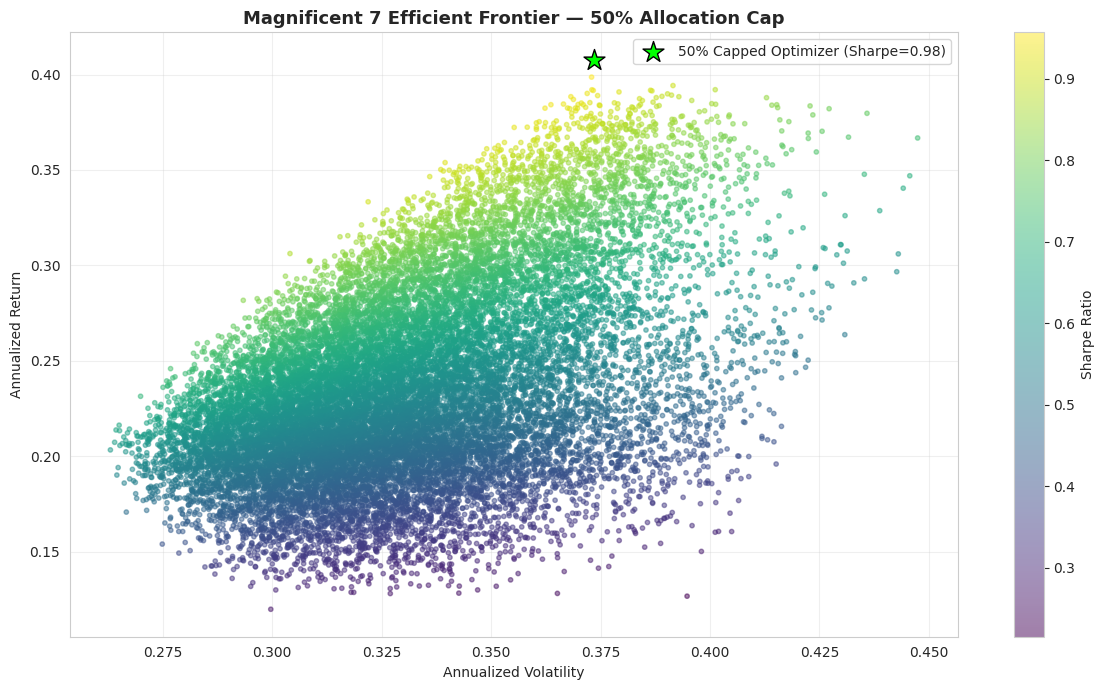

In [15]:
from scipy.optimize import minimize

# -----------------------------------
# Portfolio Optimization - MPT
# -----------------------------------

daily_returns_est = data_estimation.pct_change().dropna()
log_returns_est = np.log(data_estimation / data_estimation.shift(1)).dropna()

mean_simple_ret = daily_returns_est.mean()
cov_mat = daily_returns_est.cov()

num_portfolios = 20000
CAP = 0.50

np.random.seed(42)


def generate_feasible_weights(n_assets, n_portfolios, max_weight, seed=42):
    rng = np.random.default_rng(seed)
    weights = []

    while len(weights) < n_portfolios:
        batch = rng.dirichlet(np.ones(n_assets), size=n_portfolios)
        feasible = batch[np.max(batch, axis=1) <= max_weight]
        weights.extend(feasible.tolist())

    return np.array(weights[:n_portfolios])


weights_matrix = generate_feasible_weights(
    len(tickers),
    num_portfolios,
    CAP,
    seed=42
)

portfolio_returns = weights_matrix @ mean_simple_ret.values * 252

portfolio_volatility = np.sqrt(
    np.einsum(
        'ij,jk,ik->i',
        weights_matrix,
        cov_mat.values * 252,
        weights_matrix
    )
)

portfolio_sharpe = (
    portfolio_returns - risk_free_rate
) / portfolio_volatility

results_df = pd.DataFrame({
    'Return': portfolio_returns,
    'Volatility': portfolio_volatility,
    'Sharpe Ratio': portfolio_sharpe
})

max_sharpe_idx = results_df['Sharpe Ratio'].idxmax()

optimal_weights_random = pd.Series(
    weights_matrix[max_sharpe_idx],
    index=tickers
)


def neg_sharpe(w, mean_ret, cov_mat, rf):
    p_ret = np.dot(mean_ret, w) * 252
    p_vol = np.sqrt(w.T @ (cov_mat * 252) @ w)

    if p_vol == 0:
        return 1e6

    return -(p_ret - rf) / p_vol


n = len(tickers)

constraints = {
    'type': 'eq',
    'fun': lambda w: np.sum(w) - 1
}


def optimize_portfolio(max_weight):

    bounds = tuple(
        (0.00, max_weight) for _ in range(n)
    )

    result = minimize(
        neg_sharpe,
        np.repeat(1 / n, n),
        args=(
            mean_simple_ret.values,
            cov_mat.values,
            risk_free_rate
        ),
        method='SLSQP',
        bounds=bounds,
        constraints=constraints,
        options={
            'ftol': 1e-12,
            'maxiter': 2000
        }
    )

    if not result.success:
        raise RuntimeError(
            f"Optimization failed: {result.message}"
        )

    weights = pd.Series(result.x, index=tickers)

    ret = np.dot(
        mean_simple_ret.values,
        result.x
    ) * 252

    vol = np.sqrt(
        result.x.T
        @ (cov_mat.values * 252)
        @ result.x
    )

    sharpe = (ret - risk_free_rate) / vol

    return weights, ret, vol, sharpe


# -----------------------------------
# Unconstrained diagnostic portfolio
# -----------------------------------

(
    unconstrained_weights,
    unconstrained_ret,
    unconstrained_vol,
    unconstrained_sharpe
) = optimize_portfolio(1.00)


# -----------------------------------
# Final 50%-capped portfolio
# -----------------------------------

(
    optimal_weights,
    opt_ret,
    opt_vol,
    optimizer_sharpe
) = optimize_portfolio(CAP)


print('Portfolio Optimization Results')
print('=' * 55)

print('\nUnconstrained Maximum-Sharpe Portfolio:')
print(f'   Annualized Return    : {unconstrained_ret * 100:.2f}%')
print(f'   Annualized Volatility: {unconstrained_vol * 100:.2f}%')
print(f'   Sharpe Ratio         : {unconstrained_sharpe:.3f}')

print('\nFinal 50%-Capped Maximum-Sharpe Portfolio:')
print(f'   Annualized Return    : {opt_ret * 100:.2f}%')
print(f'   Annualized Volatility: {opt_vol * 100:.2f}%')
print(f'   Sharpe Ratio         : {optimizer_sharpe:.3f}')

print('\nFinal Optimal Weights:')
for ticker, weight in optimal_weights.items():
    print(f'   {ticker:5s}: {weight * 100:.2f}%')

print(f'\nWeight check: {optimal_weights.sum() * 100:.2f}%')
print(f'Maximum individual weight: {optimal_weights.max() * 100:.2f}%')


# -----------------------------------
# Efficient Frontier
# -----------------------------------

plt.figure(figsize=(12, 7))

plt.scatter(
    results_df['Volatility'],
    results_df['Return'],
    c=results_df['Sharpe Ratio'],
    cmap='viridis',
    marker='o',
    s=10,
    alpha=0.5
)

plt.colorbar(label='Sharpe Ratio')

plt.scatter(
    opt_vol,
    opt_ret,
    c='lime',
    marker='*',
    s=250,
    edgecolor='black',
    label=f'50% Capped Optimizer (Sharpe={optimizer_sharpe:.2f})'
)

plt.title(
    'Magnificent 7 Efficient Frontier — 50% Allocation Cap',
    fontsize=13,
    fontweight='bold'
)
plt.xlabel('Annualized Volatility')
plt.ylabel('Annualized Return')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Portfolio Optimization Findings

- The **unconstrained optimizer** is used as a diagnostic to reveal concentration risk; historical optimization can otherwise allocate an excessive share to the strongest-performing stock.
- Imposing a **50% single-stock cap** forces the optimizer to diversify the remaining capital across other attractive assets.
- The final portfolio is selected using the **highest Sharpe Ratio subject to the concentration constraint**, rather than maximizing return alone.
- The capped portfolio may have a slightly lower Sharpe Ratio than the unconstrained solution; this is an intentional risk-control tradeoff, not a model failure.
- The optimization is historical and therefore sensitive to the sample period, expected-return estimates, and covariance matrix.

## Individual Stock Monte Carlo Simulation — NVDA

A one-year Monte Carlo simulation generates **10,000 possible NVDA price paths** using a Geometric Brownian Motion-style log-return model.

The model uses the historical mean and standard deviation of **daily log returns**. Because the parameters are already daily, the simulation applies daily shocks directly rather than multiplying them by `dt` a second time.

The simulation is used to quantify uncertainty and a **99% simulated return VaR**, not to produce a deterministic price target.

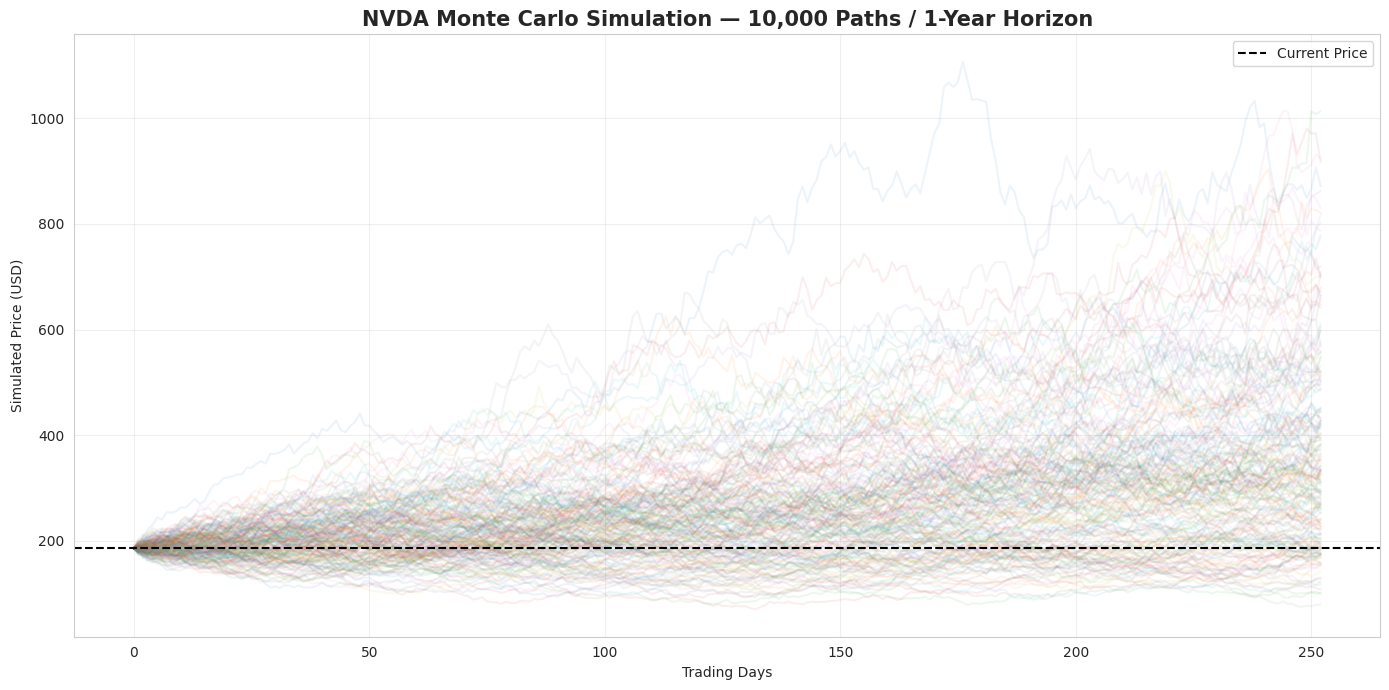

Current NVDA Price : $186.27
Median 1-Year Price   : $317.24
5th Percentile Price  : $135.52
95th Percentile Price : $738.88
99% Simulated VaR     : -49.53%


In [16]:
# -----------------------------------
# Individual Stock Monte Carlo (GBM-style)
# -----------------------------------

stock = 'NVDA'

log_ret = np.log(
    data[stock] / data[stock].shift(1)
).dropna()

mu_log = log_ret.mean()
sigma = log_ret.std()

S0 = data[stock].iloc[-1]

T = 252
N = 10000

np.random.seed(42)

simulations = np.zeros((T + 1, N))
simulations[0] = S0

for t in range(1, T + 1):

    z = np.random.standard_normal(N)

    simulations[t] = simulations[t - 1] * np.exp(
        mu_log + sigma * z
    )

final_prices = simulations[-1]

returns = (final_prices / S0 - 1) * 100

var_99 = np.percentile(returns, 1)

median_price = np.median(final_prices)
p05_price = np.percentile(final_prices, 5)
p95_price = np.percentile(final_prices, 95)


plt.figure(figsize=(14, 7))

plt.plot(
    simulations[:, :200],
    alpha=0.08
)

plt.axhline(
    S0,
    color='black',
    linestyle='--',
    label='Current Price'
)

plt.title(
    f'{stock} Monte Carlo Simulation — 10,000 Paths / 1-Year Horizon',
    fontsize=15,
    fontweight='bold'
)
plt.xlabel('Trading Days')
plt.ylabel('Simulated Price (USD)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Current {stock} Price : ${S0:.2f}')
print(f'Median 1-Year Price   : ${median_price:.2f}')
print(f'5th Percentile Price  : ${p05_price:.2f}')
print(f'95th Percentile Price : ${p95_price:.2f}')
print(f'99% Simulated VaR     : {var_99:.2f}%')

### Key Findings

- The simulated NVDA paths widen substantially over the one-year horizon, illustrating how uncertainty compounds with volatility.
- The 5th–95th percentile price range provides a more informative scenario view than a single point forecast.
- The 99% simulated VaR represents the **1st percentile of the simulated one-year return distribution**; it is not a guaranteed maximum loss.
- Because the underlying return distribution is not perfectly normal, this GBM-style simulation should be treated as a baseline scenario model rather than a complete representation of tail risk.

## Correlated Portfolio Monte Carlo Simulation

The portfolio simulation extends the individual-stock model to all seven assets.

### Key modeling step

A **Cholesky decomposition of the historical daily log-return covariance matrix** transforms independent random shocks into correlated shocks. This preserves the cross-stock dependence structure observed in the sample.

The simulation produces 10,000 joint paths over a one-year horizon and is subsequently used for portfolio-level VaR analysis.

> Portfolio VaR is calculated using **capital weights**, so each simulated stock price is normalized by its starting price before applying the portfolio weights.

In [17]:
# -----------------------------------
# Correlated Portfolio Monte Carlo
# -----------------------------------

log_returns_mc = np.log(
    data_estimation / data_estimation.shift(1)
).dropna()

start_prices = data_evaluation.iloc[0].values   

cov_matrix_mc = log_returns_mc.cov().values
mu_log_mc = log_returns_mc.mean().values

cholesky_decomp = np.linalg.cholesky(cov_matrix_mc)

days_to_simulate = 252
num_simulations = 10000

np.random.seed(42)


def portfolio_monte_carlo(
    mu_log,
    cholesky,
    start_prices,
    days,
    n_sims
):
    n_stocks = len(start_prices)

    sims = np.zeros(
        (days + 1, n_sims, n_stocks)
    )

    sims[0] = start_prices

    for t in range(1, days + 1):

        Z = np.random.standard_normal(
            (n_sims, n_stocks)
        )

        correlated_shocks = Z @ cholesky.T

        sims[t] = sims[t - 1] * np.exp(
            mu_log + correlated_shocks
        )

    return sims


print(
    f'Running {num_simulations:,} simulations '
    f'for {days_to_simulate} future trading days...'
)

portfolio_sims = portfolio_monte_carlo(
    mu_log_mc,
    cholesky_decomp,
    start_prices,
    days_to_simulate,
    num_simulations
)

print(
    f'Done! Shape: {portfolio_sims.shape} '
    f'(days+1 x simulations x stocks)'
)

Running 10,000 simulations for 252 future trading days...
Done! Shape: (253, 10000, 7) (days+1 x simulations x stocks)


### Correlated Simulation Example — AAPL

The following chart shows a subset of the correlated simulation paths for AAPL. The paths are generated jointly with all seven stocks, so the simulation preserves historical cross-asset covariance.

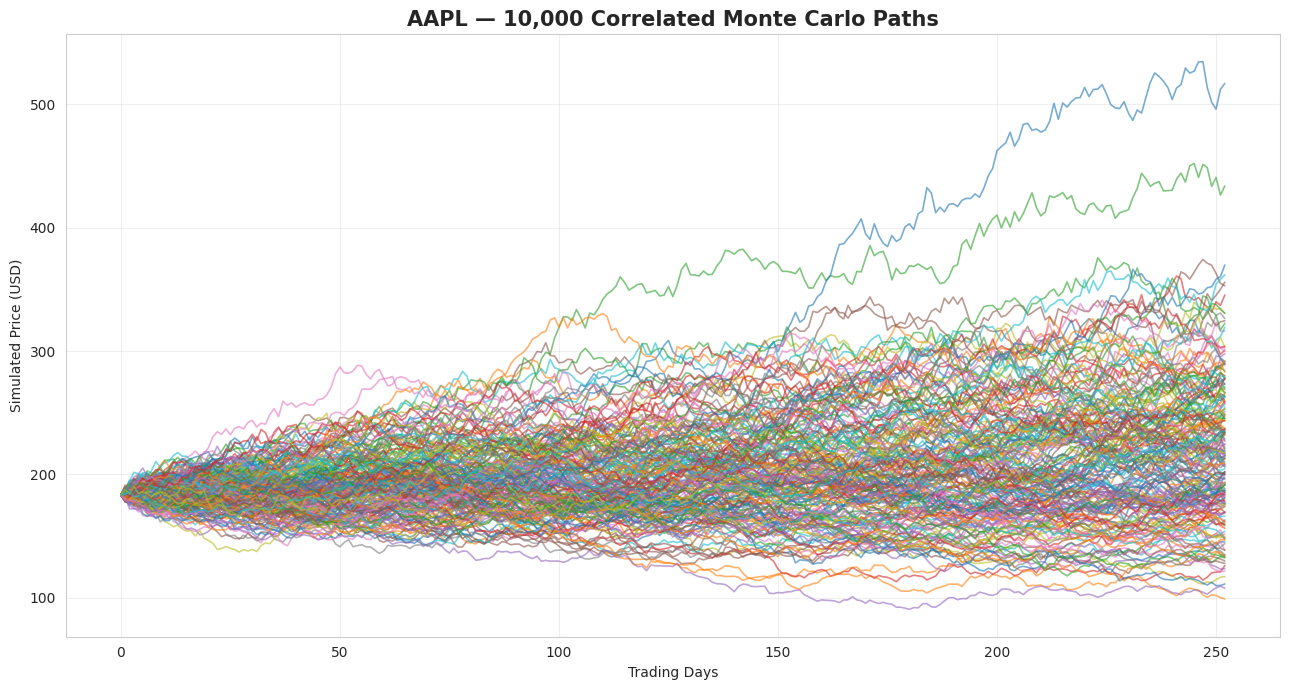

In [18]:
stock_idx = tickers.index('AAPL')
stock_name = 'AAPL'

plt.figure(figsize=(13, 7))

for i in range(200):
    plt.plot(
        portfolio_sims[:, i, stock_idx],
        linewidth=1.2,
        alpha=0.6
    )

plt.title(
    f'{stock_name} — 10,000 Correlated Monte Carlo Paths',
    fontsize=15,
    fontweight='bold'
)
plt.xlabel('Trading Days')
plt.ylabel('Simulated Price (USD)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Key Findings

- Correlated simulation produces a range of plausible future price paths while preserving historical cross-asset dependence.
- The dispersion of paths increases over time, demonstrating the compounding effect of uncertainty.
- Monte Carlo is most useful here as a **scenario-generation and risk-quantification tool**, not as an exact price-prediction model.

### Value at Risk (VaR) Comparison

VaR is reported as a **return quantile** rather than a guaranteed maximum loss.

At the 95% confidence level, the reported VaR is the **5th percentile of the simulated one-year portfolio return distribution**.

Two portfolios are compared:

1. **Equal-Weight Portfolio** — 1/7 allocation to each stock
2. **Optimal Portfolio** — weights from the 50%-capped maximum-Sharpe optimizer

This allows the project to compare risk reduction against the portfolio's expected-return improvement.

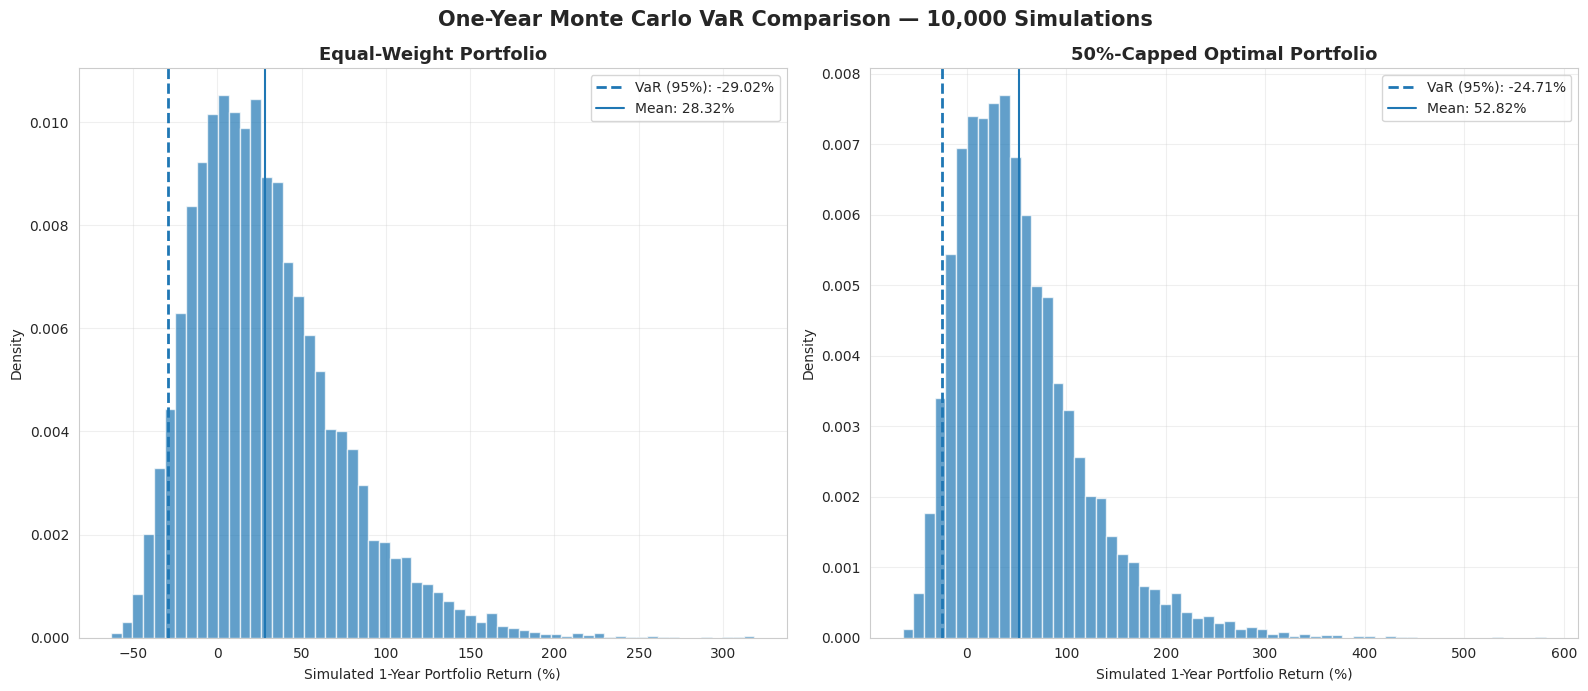

VaR Results
Equal-Weight Portfolio : 95% VaR = -29.02%
Optimal Portfolio      : 95% VaR = -24.71%
VaR Difference         : +4.30 percentage points

Interpretation: the 95% VaR is the 5th percentile of simulated one-year returns.


In [19]:
# -----------------------------------
# Portfolio Value at Risk (VaR)
# -----------------------------------

def get_var(sims, weights, prices, conf=0.95):
    # Convert simulated prices to individual asset growth factors
    growth_factors = sims[-1] / prices

    # Portfolio return using capital weights
    final_growth = growth_factors @ weights

    rets = (final_growth - 1) * 100

    var = np.percentile(
        rets,
        100 * (1 - conf)
    )

    return var, rets


equal_w = np.repeat(
    1 / len(tickers),
    len(tickers)
)

optimal_w = optimal_weights.values

var_equal, rets_equal = get_var(
    portfolio_sims,
    equal_w,
    start_prices
)

var_optimal, rets_optimal = get_var(
    portfolio_sims,
    optimal_w,
    start_prices
)


fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(16, 7)
)

for ax, rets, var, title in [
    (
        ax1,
        rets_equal,
        var_equal,
        'Equal-Weight Portfolio'
    ),
    (
        ax2,
        rets_optimal,
        var_optimal,
        '50%-Capped Optimal Portfolio'
    )
]:

    ax.hist(
        rets,
        bins=60,
        alpha=0.7,
        edgecolor='white',
        density=True
    )

    ax.axvline(
        var,
        linestyle='--',
        linewidth=2,
        label=f'VaR (95%): {var:.2f}%'
    )

    ax.axvline(
        np.mean(rets),
        linewidth=1.5,
        label=f'Mean: {np.mean(rets):.2f}%'
    )

    ax.set_title(
        title,
        fontsize=13,
        fontweight='bold'
    )
    ax.set_xlabel('Simulated 1-Year Portfolio Return (%)')
    ax.set_ylabel('Density')
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)

plt.suptitle(
    'One-Year Monte Carlo VaR Comparison — 10,000 Simulations',
    fontsize=15,
    fontweight='bold'
)
plt.tight_layout()
plt.show()


print('VaR Results')
print('=' * 50)

print(
    f'Equal-Weight Portfolio : '
    f'95% VaR = {var_equal:.2f}%'
)

print(
    f'Optimal Portfolio      : '
    f'95% VaR = {var_optimal:.2f}%'
)

print(
    f'VaR Difference         : '
    f'{var_optimal - var_equal:+.2f} percentage points'
)

print(
    '\nInterpretation: the 95% VaR is the 5th percentile '
    'of simulated one-year returns.'
)

## Rebalancing Backtest: Monthly Rebalancing vs Buy & Hold

This backtest compares two equal-weight portfolio strategies over the same historical sample:

- **Buy & Hold:** invest once at equal weights and allow allocations to drift naturally.
- **Monthly Rebalancing:** reset the portfolio to equal weights at each month-end.

The comparison evaluates whether disciplined rebalancing changes long-run portfolio growth relative to simply holding the original allocation.

> Transaction costs and taxes are not modeled, so the backtest is a simplified historical comparison.

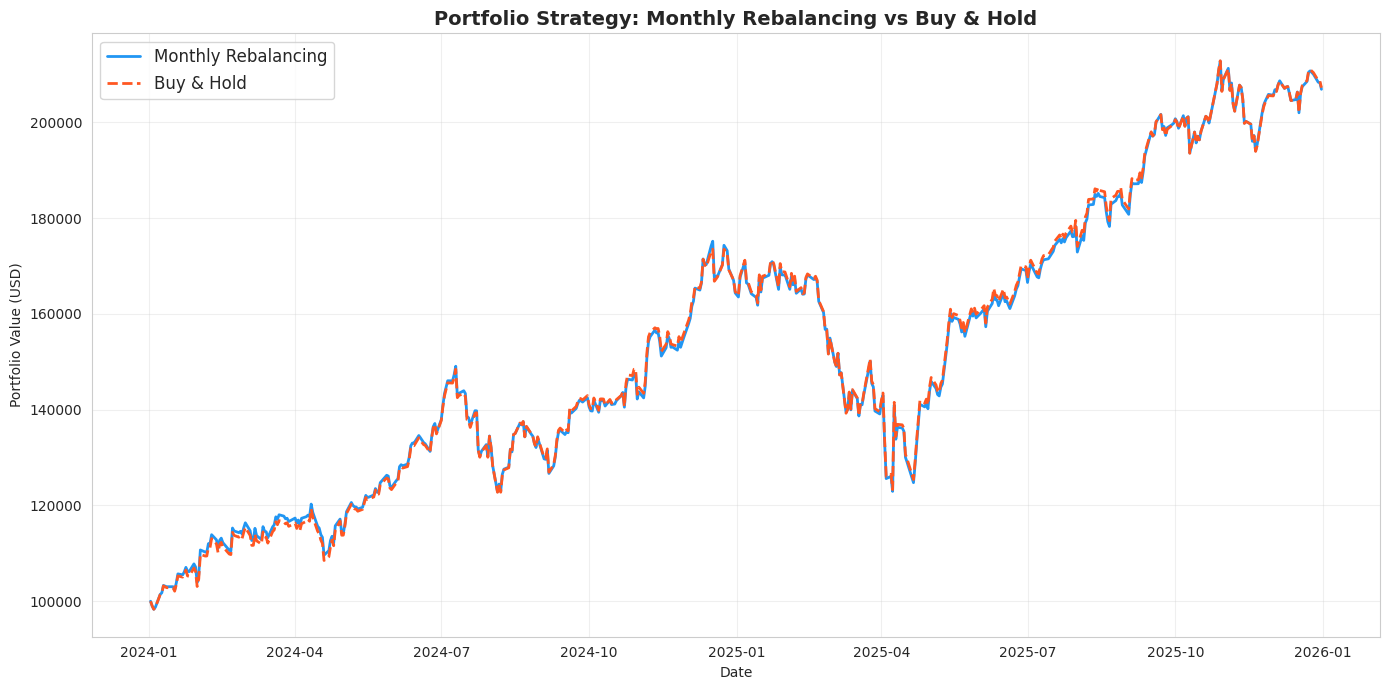

Final Portfolio Values
Monthly Rebalancing: $206,920 (+106.9%)
Buy & Hold         : $207,249 (+107.2%)


In [20]:
# -----------------------------------
# Monthly Rebalancing vs Buy & Hold
# -----------------------------------

initial_capital = 100000.0

target_w = np.repeat(
    1 / len(tickers),
    len(tickers)
)

month_end_dates = set(
    data_evaluation.resample('ME').last().index
)

portfolio_val = pd.Series(
    index=data_evaluation.index,
    dtype=float
)

shares = pd.Series(
    0.0,
    index=tickers
)

cash = initial_capital

TRANSACTION_COST_BPS = 5   # 5 basis points = 0.05% per trade — industry-standard retail assumption

for i, date in enumerate(data_evaluation.index):
    prices_today = data_evaluation.loc[date]
    if i == 0 or date in month_end_dates:
        total_val = cash if i == 0 else (shares * prices_today).sum() + cash

        if i > 0:
            # value currently held per stock BEFORE rebalancing
            current_value = shares * prices_today
            target_value = total_val * target_w
            turnover = np.abs(target_value - current_value).sum()   # total $ traded
            cost = turnover * (TRANSACTION_COST_BPS / 10000)
            total_val -= cost   # deduct cost from portfolio value

        shares = (total_val * target_w) / prices_today
        cash = 0.0
    portfolio_val.loc[date] = (shares * prices_today).sum() + cash

bh_rets = (
    data_evaluation.pct_change()
    .dropna()
    .dot(target_w)
)

bh_values = pd.Series(
    index=data_evaluation.index,
    dtype=float
)
bh_values.iloc[0] = initial_capital

bh_values.iloc[1:] = (
    initial_capital
    * (1 + bh_rets).cumprod()
)


plt.figure(figsize=(14, 7))

plt.plot(
    portfolio_val.index,
    portfolio_val.values,
    label='Monthly Rebalancing',
    color='#2196F3',
    linewidth=2
)

plt.plot(
    bh_values.index,
    bh_values.values,
    label='Buy & Hold',
    color='#FF5722',
    linewidth=2,
    linestyle='--'
)

plt.title(
    'Portfolio Strategy: Monthly Rebalancing vs Buy & Hold',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Date')
plt.ylabel('Portfolio Value (USD)')
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


rebal_ret = (
    portfolio_val.iloc[-1] / initial_capital - 1
) * 100

bh_ret = (
    bh_values.iloc[-1] / initial_capital - 1
) * 100

print('Final Portfolio Values')
print('=' * 50)

print(
    f'Monthly Rebalancing: '
    f'${portfolio_val.iloc[-1]:,.0f} '
    f'({rebal_ret:+.1f}%)'
)

print(
    f'Buy & Hold         : '
    f'${bh_values.iloc[-1]:,.0f} '
    f'({bh_ret:+.1f}%)'
)

### Backtest Findings

- Buy & Hold allows winning positions to become larger over time, which can improve returns during persistent rallies but increases concentration.
- Monthly rebalancing keeps the portfolio close to its target diversification and systematically trims outperformers while adding to underperformers.
- The better historical strategy is sample-dependent; the key portfolio-management insight is the tradeoff between **return persistence and concentration control**.

In [21]:
# -----------------------------------
# Final Project Dashboard
# -----------------------------------

final_summary = pd.DataFrame({
    'Metric': [
        'M7 cumulative return',
        'S&P 500 cumulative return',
        'QQQ cumulative return',
        'M7 maximum drawdown',
        'Unconstrained max-Sharpe',
        '50%-capped max-Sharpe',
        '50%-capped annualized return',
        '50%-capped annualized volatility',
        '50%-capped 95% VaR',
        'Equal-weight 95% VaR',
        'Monthly rebalancing return',
        'Buy & Hold return'
    ],
    'Value': [
        f'{m7_return:.2f}%',
        f'{sp500_ret:.2f}%',
        f'{qqq_ret:.2f}%',
        f'{m7_drawdown:.2f}%',
        f'{unconstrained_sharpe:.3f}',
        f'{optimizer_sharpe:.3f}',
        f'{opt_ret * 100:.2f}%',
        f'{opt_vol * 100:.2f}%',
        f'{var_optimal:.2f}%',
        f'{var_equal:.2f}%',
        f'{rebal_ret:.2f}%',
        f'{bh_ret:.2f}%'
    ]
})

print('FINAL PROJECT DASHBOARD')
print('=' * 60)
print(final_summary.to_string(index=False))

print('\nFinal 50%-Capped Allocation:')
print(
    optimal_weights.mul(100).round(2).astype(str) + '%'
)

FINAL PROJECT DASHBOARD
                          Metric   Value
            M7 cumulative return 252.63%
       S&P 500 cumulative return  84.98%
           QQQ cumulative return 104.66%
             M7 maximum drawdown -49.39%
        Unconstrained max-Sharpe   1.025
           50%-capped max-Sharpe   0.980
    50%-capped annualized return  40.77%
50%-capped annualized volatility  37.34%
              50%-capped 95% VaR -24.71%
            Equal-weight 95% VaR -29.02%
      Monthly rebalancing return 106.92%
               Buy & Hold return 107.25%

Final 50%-Capped Allocation:
AAPL     0.0%
GOOG     0.0%
META     0.0%
AMZN     0.0%
MSFT    50.0%
NVDA    50.0%
TSLA     0.0%
dtype: object
